# 第 16 章：股指、货币与期货期权

本章只有一次替换 $S_0 \to S_0e^{-qT}$，这里逐个市场地应用它，并复现本章印出的数字。
**只用 NumPy**（图用 matplotlib）。定价公式、二叉树与 quanto 模拟都逐条写出，而不是
从库里调用，于是正文里的公式与代码一一对应。

| 节 | 搭什么 | 正文 |
|---|---|---|
| 1 | 带收益率的布莱克–斯科尔斯–默顿公式、布莱克模型、`show` 辅助函数 | 式 (16.1)、(16.2)、(16.7)、(16.8) |
| 2 | 一个函数，四个市场 | 表 16.1 |
| 3 | 为组合上保险，以及财富下限所需的执行价 | 例 16.1，式 (16.3) |
| 4 | 欧元看涨期权及其权利金的四种报法 | 例 16.2，表 16.2 |
| 5 | 零成本区间远期 | 例 16.3 |
| 6 | 由三个报价构成的微笑，以及市场为何按 delta 报价 | 例 16.4，图 16.1 |
| 7 | 布莱克模型，以及期货期权的行权 | 例 16.5、16.6 |
| 8 | 美式期货期权的提前行权 | 第 16.5 节 |
| 9 | quanto 与复合货币期权，用两种方法定价 | 例 16.7、16.8，式 (16.9) |
| 10 | 隐含股息率 | 例 16.9 |
| 11 | 货币波动率为何偏低 | 表 16.5 |

每个算出的数字都与本章印出的数字并列显示；在本章的舍入精度内一致时标为 `ok`。
本章没有印出的数字则只打印计算值。第 16.10 节的境内制度差异不涉及计算，这里不重复。

## 1. 公式与核对用的辅助函数

`bsq` 即式 (16.1) 与 (16.2)，带收益率 $q$ 的布莱克–斯科尔斯–默顿公式；`black` 即
式 (16.7) 与 (16.8)。`show` 把算出的值与本章印出的值并列打印。

In [1]:
import numpy as np
from math import log, sqrt, exp, erf
from statistics import NormalDist


def N(x):
    return 0.5 * (1.0 + erf(x / sqrt(2.0)))


def show(label, got, printed, tol=None):
    # tol defaults to half a unit in the last printed digit
    if tol is None and isinstance(printed, int):
        tol = 0.5
    elif tol is None:
        s = repr(float(printed)).split(".")
        tol = 0.5 * 10 ** -len(s[1]) + 1e-12
    flag = "ok" if abs(got - printed) <= tol else "DIFFERS"
    print("%-50s %14.7g   book %12.7g   %s" % (label, got, printed, flag))


def note(label, got):
    print("%-50s %14.7g" % (label, got))


def d12(S, K, T, r, q, sig):
    d1 = (log(S / K) + (r - q + 0.5 * sig * sig) * T) / (sig * sqrt(T))
    return d1, d1 - sig * sqrt(T)


def bsq(S, K, T, r, q, sig, call=True):
    # equations (16.1) and (16.2)
    d1, d2 = d12(S, K, T, r, q, sig)
    if call:
        return S * exp(-q * T) * N(d1) - K * exp(-r * T) * N(d2)
    return K * exp(-r * T) * N(-d2) - S * exp(-q * T) * N(-d1)


def black(F, K, T, r, sig, call=True):
    # equations (16.7) and (16.8): bsq with S = F and q = r
    d1 = (log(F / K) + 0.5 * sig * sig * T) / (sig * sqrt(T))
    d2 = d1 - sig * sqrt(T)
    if call:
        return exp(-r * T) * (F * N(d1) - K * N(d2))
    return exp(-r * T) * (K * N(-d2) - F * N(-d1))

## 2. 一个函数，四个市场：表 16.1

各行之间变化的只是 $q$ 的含义。下面把同一个期权用四种方式定价：作为期货期权，
分别用 $q = r$ 的 `bsq` 和 `black`；作为例 15.1 的无股息股票，分别用 $q = 0$ 的
`bsq` 和以远期 $F_0 = S_0e^{rT}$ 为输入的 `black`。每一对中的两个数必须相同。

In [2]:
show("futures option, bsq with q = r", bsq(100, 100, 0.5, 0.04, 0.04, 0.25), 6.904)
show("futures option, black", black(100, 100, 0.5, 0.04, 0.25), 6.904)
show("Example 15.1, bsq with q = 0", bsq(58, 55, 0.5, 0.04, 0.0, 0.24), 6.1731)
show("Example 15.1, black on F0 = 58 e^{0.02}", black(58 * exp(0.02), 55, 0.5, 0.04, 0.24), 6.1731)
show("F0 for Example 15.1", 58 * exp(0.02), 59.1717)

futures option, bsq with q = r                           6.903733   book        6.904   ok
futures option, black                                    6.903733   book        6.904   ok
Example 15.1, bsq with q = 0                             6.173103   book       6.1731   ok
Example 15.1, black on F0 = 58 e^{0.02}                  6.173103   book       6.1731   ok
F0 for Example 15.1                                      59.17168   book      59.1717   ok


## 3. 为组合上保险：例 16.1 与式 (16.3)

一只 3000 万美元的基金跟踪点位为 1,500 的指数，买入 200 份执行价 1,425 的六个月
看跌期权。权利金是组合的 2.48%；它给期末财富提供的下限也不是想要的 2,850 万美元：
另有约 30 万美元股息进账，权利金则要扣掉。

In [3]:
S0, K, r, q, sig, T = 1500.0, 1425.0, 0.04, 0.02, 0.18, 0.5
port, mult = 30e6, 100
n_puts = port / (S0 * mult)
put = bsq(S0, K, T, r, q, sig, call=False)
premium = n_puts * mult * put
divs = port * q * T

show("contracts", n_puts, 200)
show("put (index points)", put, 37.27)
show("cost ($), put rounded to 37.27", n_puts * mult * round(put, 2), 745400)
show("cost (% of portfolio)", 100 * premium / port, 2.48)
show("wealth at 1,425 before the put pays ($m)", (port * K / S0 + divs) / 1e6, 28.8)
show("wealth at 1,425 net of the premium ($m)", (port * K / S0 + divs - premium) / 1e6, 28.05)


def terminal_wealth(ST):
    # index tracker: price return, plus the dividends, plus the puts, less the premium
    return port * ST / S0 + divs + n_puts * mult * np.maximum(K - ST, 0.0) - premium

contracts                                                     200   book          200   ok
put (index points)                                       37.27446   book        37.27   ok
cost ($), put rounded to 37.27                             745400   book       745400   ok
cost (% of portfolio)                                    2.484964   book         2.48   ok
wealth at 1,425 before the put pays ($m)                     28.8   book         28.8   ok
wealth at 1,425 net of the premium ($m)                  28.05451   book        28.05   ok


图中，指数低于执行价时的财富下限是 2,805 万美元，这正是例题要说的：执行价决定下限，
而这个执行价是为另一个量选的。

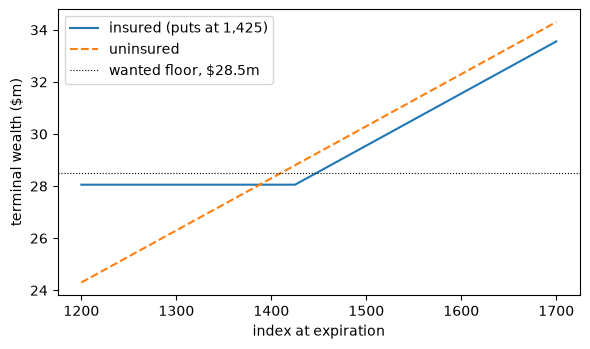

In [4]:
try:
    import matplotlib.pyplot as plt
    ST = np.linspace(1200, 1700, 201)
    plt.figure(figsize=(6, 3.6))
    plt.plot(ST, terminal_wealth(ST) / 1e6, label="insured (puts at 1,425)")
    plt.plot(ST, (port * ST / S0 + divs) / 1e6, "--", label="uninsured")
    plt.axhline(28.5, color="k", ls=":", lw=0.8, label="wanted floor, $28.5m")
    plt.xlabel("index at expiration")
    plt.ylabel("terminal wealth ($m)")
    plt.legend()
    plt.tight_layout()
    plt.show()
except ImportError:
    pass

式 (16.3) 给出贝塔为 $\beta$ 的组合所需的执行价。取 $\beta = 1.5$、含股息的财富下限
为 0.95，看跌期权的执行价上移到 1,445，合约数增至 300 份。下面的循环显示执行价如何
随贝塔变化；$\beta = 1$ 时就是单凭股息论证得到的 1,410。

In [5]:
def floor_strike_ratio(wealth_ratio, beta, qV, q, r, T):
    # equation (16.3); wealth_ratio is V_T/V_0 + q_V T, the floor including dividends
    return (wealth_ratio) / beta - q * T + (1.0 - 1.0 / beta) * exp(r * T)


ratio = floor_strike_ratio(0.95, 1.5, 0.02, 0.02, 0.04, 0.5)
show("S_T / S_0, beta = 1.5", ratio, 0.9634)
show("strike", round(S0 * ratio), 1445)
show("index fall at the floor (%)", 100 * (1 - ratio), 3.7)
show("contracts, beta x 200", 1.5 * n_puts, 300)

print()
print("%6s %10s %10s" % ("beta", "strike", "contracts"))
for beta in (0.5, 0.8, 1.0, 1.2, 1.5, 2.0):
    k = S0 * floor_strike_ratio(0.95, beta, 0.02, 0.02, 0.04, 0.5)
    print("%6.1f %10.1f %10.0f" % (beta, k, beta * n_puts))

S_T / S_0, beta = 1.5                                   0.9634004   book       0.9634   ok
strike                                                       1445   book         1445   ok
index fall at the floor (%)                              3.659955   book          3.7   ok
contracts, beta x 200                                         300   book          300   ok

  beta     strike  contracts
   0.5     1304.7        100
   0.8     1383.7        160
   1.0     1410.0        200
   1.2     1427.6        240
   1.5     1445.1        300
   2.0     1462.7        400


## 4. 欧元看涨期权：例 16.2 与表 16.2

本币是美元，故 $r = 4\%$，$q = r_f = 2.5\%$。表 16.2 中权利金的四种报法，是同一个数
分别除以或乘以不同的量。最后几行计算第 16.4 节区分的几种 delta，本章只给出名称，
没有印出数值。

In [6]:
S, K, r, rf, sig, T = 1.0850, 1.1000, 0.04, 0.025, 0.08, 0.5
d1, d2 = d12(S, K, T, r, rf, sig)
c = bsq(S, K, T, r, rf, sig)
F = S * exp((r - rf) * T)

show("d1", d1, -0.0819)
show("d2", d2, -0.1384)
show("N(d1)", N(d1), 0.467383)
show("N(d2)", N(d2), 0.444954)
show("call ($ per euro)", c, 0.02105)
show("premium on 1m euros ($)", 1e6 * c, 21053)
show("forward", F, 1.09317)
show("risk-neutral exercise probability (%)", 100 * N(d2), 44.5)
print()
print("Table 16.2")
show("  domestic per unit foreign", c, 0.02105)
show("  % of foreign notional, c / S0", 100 * c / S, 1.940)
show("  % of domestic notional, c / K", 100 * c / K, 1.914)
show("  domestic cash ($)", 1e6 * c, 21053)
print()
spot_delta = exp(-rf * T) * N(d1)
note("spot delta, e^{-r_f T} N(d1)", spot_delta)
note("forward delta, N(d1)", N(d1))
note("premium-adjusted spot delta, delta - c/S0", spot_delta - c / S)

d1                                                    -0.08185102   book      -0.0819   ok
d2                                                     -0.1384196   book      -0.1384   ok
N(d1)                                                   0.4673826   book     0.467383   ok
N(d2)                                                   0.4449544   book     0.444954   ok
call ($ per euro)                                      0.02105259   book      0.02105   ok
premium on 1m euros ($)                                  21052.59   book        21053   ok
forward                                                  1.093168   book      1.09317   ok
risk-neutral exercise probability (%)                    44.49544   book         44.5   ok

Table 16.2
  domestic per unit foreign                            0.02105259   book      0.02105   ok
  % of foreign notional, c / S0                           1.94033   book         1.94   ok
  % of domestic notional, c / K                          1.913871   book      

## 5. 零成本区间远期：例 16.3

进口商买入执行价 1.1300 的看涨期权，卖出价值与之相等的看跌期权。看跌期权的价值随
执行价上升，所以用二分法求执行价。图中比较了区间远期、远期与不对冲三种情形下，
买入 100 万欧元的美元成本。

call at 1.1300                                         0.01063468   book      0.01063   ok
put strike, same value                                   1.058748   book       1.0587   ok
cost of 1m euros at the put strike ($)                    1058748   book      1058748   ok
cost under the forward ($)                                1093168   book      1093168   ok
band below the forward (%)                               3.148696   book          3.1   ok
band above the forward (%)                               3.369281   book          3.4   ok


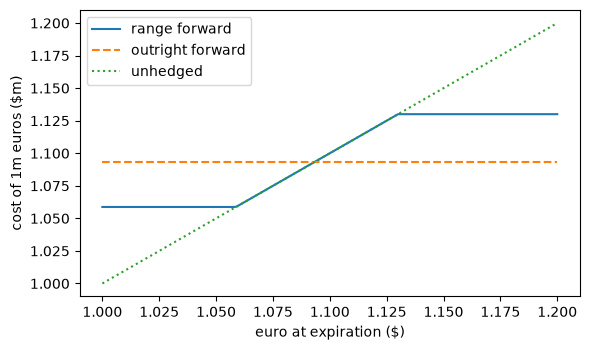

In [7]:
Kc = 1.1300
c113 = bsq(S, Kc, T, r, rf, sig)
lo, hi = 0.90, S
for _ in range(100):
    mid = 0.5 * (lo + hi)
    if bsq(S, mid, T, r, rf, sig, call=False) < c113:
        lo = mid
    else:
        hi = mid
Kp = mid

show("call at 1.1300", c113, 0.01063)
show("put strike, same value", Kp, 1.0587)
show("cost of 1m euros at the put strike ($)", 1e6 * Kp, 1058748, tol=5)
show("cost under the forward ($)", 1e6 * F, 1093168, tol=5)
show("band below the forward (%)", 100 * (1 - Kp / F), 3.1)
show("band above the forward (%)", 100 * (Kc / F - 1), 3.4)

try:
    import matplotlib.pyplot as plt
    ST = np.linspace(1.00, 1.20, 201)
    plt.figure(figsize=(6, 3.6))
    plt.plot(ST, 1e6 * np.clip(ST, Kp, Kc) / 1e6, label="range forward")
    plt.plot(ST, np.full_like(ST, F), "--", label="outright forward")
    plt.plot(ST, ST, ":", label="unhedged")
    plt.xlabel("euro at expiration ($)")
    plt.ylabel("cost of 1m euros ($m)")
    plt.legend()
    plt.tight_layout()
    plt.show()
except ImportError:
    pass

## 6. 由三个报价构成的微笑：例 16.4 与图 16.1

由式 (16.5) 与 (16.6) 解出两个 25-delta 波动率。然后求这两个 delta 对应的执行价，
这里把 delta 取为不经权利金调整的远期 delta $N(d_1)$，即第 16.4 节列出的惯例之一；
换一种惯例，同样的报价会给出略有不同的执行价。

In [8]:
atm, rr, bf = 8.00, -0.60, 0.25
vol_25c = atm + bf + rr / 2
vol_25p = atm + bf - rr / 2
show("25-delta call volatility (%)", vol_25c, 7.95)
show("25-delta put volatility (%)", vol_25p, 8.55)


def strike_from_forward_delta(delta, vol, F, T, call=True):
    # N(d1) = delta for a call, N(d1) - 1 = delta for a put
    d1 = NormalDist().inv_cdf(delta if call else 1.0 + delta)
    return F * exp(-d1 * vol * sqrt(T) + 0.5 * vol * vol * T)


k25c = strike_from_forward_delta(0.25, vol_25c / 100, F, T, call=True)
k25p = strike_from_forward_delta(-0.25, vol_25p / 100, F, T, call=False)
note("forward", F)
note("25-delta call strike", k25c)
note("25-delta put strike", k25p)

25-delta call volatility (%)                                 7.95   book         7.95   ok
25-delta put volatility (%)                                  8.55   book         8.55   ok
forward                                                  1.093168
25-delta call strike                                     1.137208
25-delta put strike                                      1.051407


为什么按 delta 报价：决定期权价格的距离是 $\ln(K/F_0)/(\sigma\sqrt{T})$。对固定的
执行价，即使远期不动，这个距离也会随时间漂移；而 25-delta 执行价每天重新求解，按
构造始终处在同一距离上。下表把远期固定在 1.09317、波动率固定在 8%。

In [9]:
print("%12s %22s %22s" % ("T (years)", "fixed K = 1.1300", "25-delta call strike"))
for t in (0.5, 0.25, 1 / 12, 1 / 52):
    kd = strike_from_forward_delta(0.25, 0.08, F, t, call=True)
    dist_fixed = log(1.1300 / F) / (0.08 * sqrt(t))
    dist_delta = log(kd / F) / (0.08 * sqrt(t))
    print("%12.4f %22.3f %22.3f" % (t, dist_fixed, dist_delta))

   T (years)       fixed K = 1.1300   25-delta call strike
      0.5000                  0.586                  0.703
      0.2500                  0.828                  0.694
      0.0833                  1.435                  0.686
      0.0192                  2.987                  0.680


## 7. 布莱克模型与期货期权的行权：例 16.5、16.6

$K = F_0$ 时看涨与看跌相等，这就是以远期表示的看跌–看涨平价关系。在期货式保证金
下权利金并不预先支付，于是贴现因子消失，价值就是方括号本身，即 7.043。

In [10]:
F0, K, r, sig, T = 100.0, 100.0, 0.04, 0.25, 0.5
d1 = (log(F0 / K) + 0.5 * sig * sig * T) / (sig * sqrt(T))
d2 = d1 - sig * sqrt(T)
show("d1", d1, 0.0884)
show("N(d1)", N(d1), 0.535216)
show("N(d2)", N(d2), 0.464784)
show("bracket, F0 N(d1) - K N(d2)", F0 * N(d1) - K * N(d2), 7.043)
show("call", black(F0, K, T, r, sig), 6.904)
show("put", black(F0, K, T, r, sig, call=False), 6.904)
note("futures-style margined call, no discount factor", F0 * N(d1) - K * N(d2))

d1                                                     0.08838835   book       0.0884   ok
N(d1)                                                    0.535216   book     0.535216   ok
N(d2)                                                    0.464784   book     0.464784   ok
bracket, F0 N(d1) - K N(d2)                              7.043198   book        7.043   ok
call                                                     6.903733   book        6.904   ok
put                                                      6.903733   book        6.904   ok
futures-style margined call, no discount factor          7.043198


例 16.6：执行价 70.00 美元的原油看涨期权的持有人在期货价为 73.40 美元时提交行权；
通知在收盘后按 73.85 美元的结算价处理。决定之后的 450 美元变动加到看涨期权上、
从看跌期权中扣除，两者最终都得到按结算价计的内在价值。

In [11]:
size, intraday, settle = 1000, 73.40, 73.85
call_k, put_k = 70.00, 76.00
show("call: intrinsic value at 73.40 ($)", size * (intraday - call_k), 3400)
show("move from 73.40 to settlement ($)", size * (settle - intraday), 450)
show("call: total ($)", size * (intraday - call_k) + size * (settle - intraday), 3850)
show("call: settlement less strike ($)", size * (settle - call_k), 3850)
show("put: intrinsic value at 73.40 ($)", size * (put_k - intraday), 2600)
show("put: total ($)", size * (put_k - intraday) - size * (settle - intraday), 2150)
show("put: strike less settlement ($)", size * (put_k - settle), 2150)

call: intrinsic value at 73.40 ($)                           3400   book         3400   ok
move from 73.40 to settlement ($)                             450   book          450   ok
call: total ($)                                              3850   book         3850   ok
call: settlement less strike ($)                             3850   book         3850   ok
put: intrinsic value at 73.40 ($)                            2600   book         2600   ok
put: total ($)                                               2150   book         2150   ok
put: strike less settlement ($)                              2150   book         2150   ok


## 8. 美式期货期权的提前行权：第 16.5 节

在无股息股票上建一棵 Cox–Ross–Rubinstein 树，就能同时为两种标的定价：在即期价为 $S$、
时间为 $t$ 的节点上，与期权同时到期的期货价格为 $Se^{r(T-t)}$。随着步数增加，欧式
期货看涨期权收敛到布莱克模型的 6.904。美式期货看涨期权的价值高于欧式，而问题中
没有任何股息；美式现货看涨期权则恰好等于其欧式价值。由于期货价格高于即期（期货
升水），美式期货看涨期权高于美式现货看涨期权，美式期货看跌期权则低于美式现货
看跌期权，这正是第 16.5 节给出的排序。

In [12]:
def crr(S0, K, T, r, sig, steps, on_futures, call, american):
    dt = T / steps
    u = exp(sig * sqrt(dt))
    d = 1.0 / u
    p = (exp(r * dt) - d) / (u - d)
    disc = exp(-r * dt)
    sign = 1.0 if call else -1.0

    def exercise(i, j):
        s = S0 * u ** j * d ** (i - j)
        x = s * exp(r * (T - i * dt)) if on_futures else s
        return max(sign * (x - K), 0.0)

    v = np.array([exercise(steps, j) for j in range(steps + 1)])
    for i in range(steps - 1, -1, -1):
        v = disc * (p * v[1:] + (1 - p) * v[:-1])
        if american:
            v = np.maximum(v, [exercise(i, j) for j in range(i + 1)])
    return float(v[0])


S0, K, T, r, sig = 100 * exp(-0.04 * 0.5), 100.0, 0.5, 0.04, 0.25   # futures price 100
show("European futures call, 2,000 steps", crr(S0, K, T, r, sig, 2000, True, True, False), 6.904, tol=0.002)
print()
print("%-12s %12s %12s %12s %12s" % ("strike", "Eur fut C", "Amer fut C", "Amer spot C", "Eur spot C"))
for k in (70.0, 85.0, 100.0):
    print("%-12.1f %12.4f %12.4f %12.4f %12.4f" % (
        k, crr(S0, k, T, r, sig, 1000, True, True, False), crr(S0, k, T, r, sig, 1000, True, True, True),
        crr(S0, k, T, r, sig, 1000, False, True, True), bsq(S0, k, T, r, 0.0, sig)))
print()
print("%-12s %12s %12s" % ("strike", "Amer fut P", "Amer spot P"))
for k in (100.0, 115.0, 130.0):
    print("%-12.1f %12.4f %12.4f" % (
        k, crr(S0, k, T, r, sig, 1000, True, False, True), crr(S0, k, T, r, sig, 1000, False, False, True)))

European futures call, 2,000 steps                       6.904563   book        6.904   ok

strike          Eur fut C   Amer fut C  Amer spot C   Eur spot C


70.0              29.5227      30.0010      29.5227      29.5230


85.0              16.2479      16.3678      16.2479      16.2476


100.0              6.9043       6.9303       6.9043       6.9037

strike         Amer fut P  Amer spot P


100.0              6.9303       7.1187


115.0             17.0829      17.7634


130.0             30.3383      31.9801


## 9. quanto 与复合货币期权，用两种方法定价：例 16.7、16.8

先算闭式解：quanto 远期式 (16.9) 加上 20% 波动率下的布莱克模型；复合货币期权则以
本币计价的指数为标的，波动率为 $\sqrt{\sigma_V^2 + \sigma_S^2 + 2\rho\sigma_V\sigma_S}$。

In [13]:
V0, qf, rf, r, sV, sS, rho, K, T = 3000.0, 0.02, 0.01, 0.04, 0.20, 0.10, 0.3, 3100.0, 1.0

Fq = V0 * exp((rf - qf - rho * sV * sS) * T)   # equation (16.9)
Fu = V0 * exp((rf - qf) * T)                   # forward without the adjustment
show("quanto forward", Fq, 2952.38)
show("unadjusted forward", Fu, 2970.15)
show("adjustment (points)", Fu - Fq, 17.77)
show("adjustment (%)", 100 * (Fu - Fq) / Fu, 0.60)
d1 = (log(Fq / K) + 0.5 * sV * sV * T) / (sV * sqrt(T))
show("d1", d1, -0.1439)
show("d2", d1 - sV * sqrt(T), -0.3439)
cq = black(Fq, K, T, r, sV)
cu = black(Fu, K, T, r, sV)
show("quanto call", cq, 167.52)
show("call without the adjustment", cu, 175.18)
show("error in the option (%)", 100 * (cu / cq - 1), 4.6)
show("magnification, option error / forward error", (cu / cq - 1) / ((Fu - Fq) / Fu), 7.6)
print()
s_compo = sqrt(sV**2 + sS**2 + 2 * rho * sV * sS)
Fc = V0 * exp((r - qf) * T)
cc = black(Fc, K, T, r, s_compo)
show("composite volatility (%)", 100 * s_compo, 24.90)
show("composite forward", Fc, 3060.60)
show("composite call", cc, 274.69)
show("composite over quanto (%)", 100 * (cc / cq - 1), 64)
note("quanto call if rho were -0.3", black(V0 * exp((rf - qf + 0.3 * sV * sS) * T), K, T, r, sV))

quanto forward                                           2952.382   book      2952.38   ok
unadjusted forward                                        2970.15   book      2970.15   ok
adjustment (points)                                      17.76754   book        17.77   ok
adjustment (%)                                          0.5982036   book          0.6   ok
d1                                                     -0.1439491   book      -0.1439   ok
d2                                                     -0.3439491   book      -0.3439   ok
quanto call                                              167.5195   book       167.52   ok
call without the adjustment                              175.1793   book       175.18   ok
error in the option (%)                                  4.572492   book          4.6   ok
magnification, option error / forward error              7.643705   book          7.6   ok

composite volatility (%)                                  24.8998   book         24.9   o

第二种定价完全不用 quanto 调整。它在**外币**风险中性测度下进行：指数的漂移率为
$r_f - q_f$；从境外看，本币是赚取 $r$ 的资产，于是 $X = 1/S$ 的漂移率为 $r_f - r$，
与指数的相关系数为 $-\rho$。一笔本币收益 $P_T$ 在到期时值 $P_T/S_T$ 外币，故今天的
本币价值为 $S_0\,E^f[e^{-r_fT}P_T/S_T] = E^f[e^{-r_fT}P_TX_T]$（取 $S_0 = 1$）。若
式 (16.9) 的调整正确，这个模拟应在标准误差范围内落在 167.52 上；同一个模拟也给出
复合货币期权的价格。本章把推导留给第 30 章；这一步说明，公式不必凭信任接受。

In [14]:
rng = np.random.default_rng(16)
n = 1_000_000
z = rng.standard_normal(n)
w = -rho * z + sqrt(1 - rho**2) * rng.standard_normal(n)   # correlation -rho with z
z, w = np.concatenate([z, -z]), np.concatenate([w, -w])     # antithetic pairs

VT = V0 * np.exp((rf - qf - 0.5 * sV**2) * T + sV * sqrt(T) * z)   # foreign measure
XT = np.exp((rf - r - 0.5 * sS**2) * T + sS * sqrt(T) * w)         # foreign per domestic
ST_fx = 1.0 / XT                                                    # domestic per foreign


def price_foreign_measure(payoff):
    x = exp(-rf * T) * payoff * XT
    pairs = 0.5 * (x[:n] + x[n:])
    return pairs.mean(), pairs.std() / sqrt(n)


mq, se_q = price_foreign_measure(np.maximum(VT - K, 0.0))
mc, se_c = price_foreign_measure(np.maximum(VT * ST_fx - K, 0.0))
show("quanto call, foreign-measure simulation", mq, 167.52, tol=3 * se_q)
note("  standard error", se_q)
show("composite call, foreign-measure simulation", mc, 274.69, tol=3 * se_c)
note("  standard error", se_c)

quanto call, foreign-measure simulation                  167.7622   book       167.52   ok
  standard error                                        0.1904461
composite call, foreign-measure simulation               274.7097   book       274.69   ok
  standard error                                        0.2521988


例 16.8 的收益表，以及 quanto 价格随相关系数的变化。quanto 只按指数支付；复合货币
期权则同时按指数与汇率支付。

   index       FX    quanto pays   composite pays
    3400     0.90            300                0
    3400     1.00            300              300
    3400     1.10            300              640
    3100     1.10              0              310
    2800     0.90              0                0
    2800     1.10              0                0


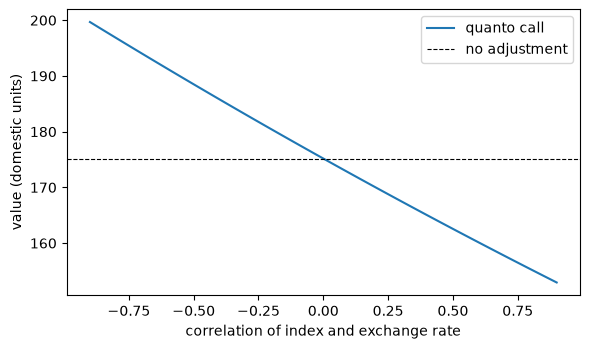

In [15]:
print("%8s %8s %14s %16s" % ("index", "FX", "quanto pays", "composite pays"))
for idx, fx in ((3400, 0.90), (3400, 1.00), (3400, 1.10), (3100, 1.10), (2800, 0.90), (2800, 1.10)):
    print("%8d %8.2f %14.0f %16.0f" % (idx, fx, max(idx - K, 0), max(idx * fx - K, 0)))

try:
    import matplotlib.pyplot as plt
    rhos = np.linspace(-0.9, 0.9, 91)
    qc = [black(V0 * exp((rf - qf - rh * sV * sS) * T), K, T, r, sV) for rh in rhos]
    plt.figure(figsize=(6, 3.6))
    plt.plot(rhos, qc, label="quanto call")
    plt.axhline(cu, color="k", ls="--", lw=0.8, label="no adjustment")
    plt.xlabel("correlation of index and exchange rate")
    plt.ylabel("value (domestic units)")
    plt.legend()
    plt.tight_layout()
    plt.show()
except ImportError:
    pass

## 10. 隐含股息率：例 16.9

仅凭平价关系就能得到股息率，不涉及波动率。最后几行验证这一点：在这个股息率下，
布莱克–斯科尔斯–默顿看涨减看跌，无论用什么波动率都是 7.30。

In [16]:
S0, K, r, T, c_minus_p = 1500.0, 1500.0, 0.04, 0.5, 68.50 - 61.20
KeRT = K * exp(-r * T)
SeqT = c_minus_p + KeRT
show("K e^{-rT}", KeRT, 1470.30)
show("S e^{-qT}", SeqT, 1477.60)
show("e^{-0.5q}, from the rounded 1,477.60", round(SeqT, 2) / S0, 0.985067)
q_impl = -log(SeqT / S0) / T
show("implied q (%)", 100 * q_impl, 3.01)
for vol in (0.10, 0.20, 0.40):
    cp = bsq(S0, K, T, r, q_impl, vol) - bsq(S0, K, T, r, q_impl, vol, call=False)
    show("c - p at q_impl, sigma = %.0f%%" % (100 * vol), cp, 7.30)

K e^{-rT}                                                1470.298   book       1470.3   ok
S e^{-qT}                                                1477.598   book       1477.6   ok
e^{-0.5q}, from the rounded 1,477.60                    0.9850667   book     0.985067   ok
implied q (%)                                            3.009461   book         3.01   ok
c - p at q_impl, sigma = 10%                                  7.3   book          7.3   ok
c - p at q_impl, sigma = 20%                                  7.3   book          7.3   ok
c - p at q_impl, sigma = 40%                                  7.3   book          7.3   ok


## 11. 货币波动率为何偏低：表 16.5

汇率是两种货币价值之比，由式 (14.19)，其波动率为
$\sqrt{\sigma_1^2 + \sigma_2^2 - 2\rho\sigma_1\sigma_2}$。两个各为 15% 的分量，随着
相关系数上升，给出的波动率从 21% 一路降到几个百分点。

In [17]:
print("%8s %16s" % ("rho", "ratio vol (%)"))
for rh in (0.0, 0.5, 0.8, 0.9, 0.95):
    print("%8.2f %16.2f" % (rh, 100 * sqrt(2 * 0.15**2 - 2 * rh * 0.15**2)))

     rho    ratio vol (%)
    0.00            21.21
    0.50            15.00
    0.80             9.49
    0.90             6.71
    0.95             4.74


## 这个 notebook 说明了什么

* 一个函数就能为股指、货币与期货期权定价，变的只是 $q$ 的含义；布莱克模型就是这个
  函数在 $q = r$ 时的形式。
* 看跌期权的执行价给指数设下限，而不是给财富设下限。股息、权利金和贝塔都会改变
  真正的财富下限所需的执行价。
* 外汇权利金有四种正确的报法；市场按 delta 报价，是因为在决定价格的距离上，
  执行价会漂移而 delta 不会。
* 即使问题中没有股息，美式期货看涨期权也可能值得提前行权；在期货升水时，它比以
  即期为标的的美式看涨期权更值钱。
* quanto 调整在另一个测度下得到复现，而该模拟从未用到它；远期 0.6% 的误差
  变成期权 4.6% 的误差。

上面所有确定性的数字都复现了本章；本笔记本第 9 节的模拟与闭式解的差距在三个标准误差之内。